# Public Transport Insight
**MetroLink Transit Services** (fictional assessment scenario) · Smart City / Public Transportation

Objective: measure passenger demand and operational reliability, then test a one-hour-ahead
route-level boarding forecast. The Kaggle Public Transportation Usage Dataset is **fully synthetic**,
inspired by transit systems, and is only a proxy for the challenge scenario. No causal or
real-world operational claims follow from these simulated observations.

In [5]:
from pathlib import Path
from time import perf_counter
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

sns.set_theme(style="whitegrid", palette="deep")
ROOT = Path.cwd().resolve()
if not (ROOT / "metadata/metadata.json").is_file():
    ROOT = ROOT.parent
assert (ROOT / "metadata/metadata.json").is_file(), "Run from the repository root or notebook directory"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
paths = {
    "train": ROOT / "data/splits/transit_train.csv/train.csv",
    "validation": ROOT / "data/splits/transit_val.csv/val.csv",
    "test": ROOT / "data/splits/transit_test.csv/test.csv",
}
assert all(p.is_file() for p in paths.values()), "A split CSV is missing"
metadata = json.loads((ROOT / "metadata/metadata.json").read_text())
print("Dataset source:", metadata["data_sources"][0])
print("Target:", metadata["ml_tasks"]["time_series_forecasting"]["target"])

Dataset source: Fully synthetic inspired by GTFS feeds, Transport for London, MTA NYC, VBB Berlin, RATP Paris
Target: boarding_count


## 2. Dataset understanding
The supplied train, validation, and test files are disjoint partitions of the complete
569,400-observation collection. The separate `processed.csv` and `transit_fe.csv` files are
overlapping 500,000-row subsets and must never be appended to these partitions. We read
only fields needed for analysis, and audit all 88 source fields in chunks below.

In [6]:
columns = ["trip_id", "timestamp", "route_id", "city", "route_type", "origin_station",
           "dest_station", "boarding_count", "alighting_count", "passenger_count",
           "occupancy_rate", "delay_minutes", "service_status", "cancellation_flag",
           "weather_condition", "temperature_c", "route_length_km", "headway_min",
           "vehicle_capacity", "is_weekend", "is_holiday"]
parts = {name: pd.read_csv(path, usecols=columns, parse_dates=["timestamp"])
         for name, path in paths.items()}
df = pd.concat(parts.values(), ignore_index=True)
source_columns = pd.read_csv(paths["train"], nrows=0).columns.tolist()
assert len(source_columns) == 88
assert df.trip_id.is_unique
assert len(df) == metadata["n_rows_total"]
print(f"Records: {len(df):,}; source attributes: {len(source_columns)}")
print("Loaded analysis fields and types:")
display(df.dtypes.to_frame("dtype"))
print("First five records:")
display(df.head())
print("Descriptive statistics:")
display(df.describe(include="all", datetime_is_numeric=False) if pd.__version__.startswith("1.") else df.describe(include="all"))
print("Unique cities, routes, origin stations, modes:",
      *(df[c].nunique() for c in ["city", "route_id", "origin_station", "route_type"]))
print("Date range:", df.timestamp.min(), "to", df.timestamp.max())
print("Loaded-frame memory (MiB):", round(df.memory_usage(deep=True).sum() / 2**20, 1))

Records: 569,400; source attributes: 88
Loaded analysis fields and types:


,dtype
trip_id,str
timestamp,datetime64[us]
route_id,str
city,str
route_type,str
origin_station,str
dest_station,str
boarding_count,int64
alighting_count,int64
passenger_count,int64


First five records:


,trip_id,timestamp,route_id,city,route_type,origin_station,dest_station,boarding_count,alighting_count,passenger_count,...,delay_minutes,service_status,cancellation_flag,weather_condition,temperature_c,route_length_km,headway_min,vehicle_capacity,is_weekend,is_holiday
0,TRIP_RT_BER_000_0000000,2020-01-01,RT_BER_000,Berlin,tram,STN_BER_0113,STN_BER_0198,0,0,0,...,0,on_time,0,clear,4.98,40.1,6,150,0,1
1,TRIP_RT_LON_000_0000000,2020-01-01,RT_LON_000,London,rail,STN_LON_0066,STN_LON_0009,0,0,0,...,0,on_time,0,clear,3.72,48.7,59,600,0,1
2,TRIP_RT_NEW_000_0000000,2020-01-01,RT_NEW_000,New_York,bus,STN_NEW_0136,STN_NEW_0045,0,0,0,...,0,on_time,0,clear,7.81,36.9,14,80,0,1
3,TRIP_RT_PAR_014_0000000,2020-01-01,RT_PAR_014,Paris,bus,STN_PAR_0279,STN_PAR_0030,0,0,0,...,6,on_time,0,light_rain,2.01,18.4,17,80,0,1
4,TRIP_RT_TOK_005_0000000,2020-01-01,RT_TOK_005,Tokyo,metro,STN_TOK_0007,STN_TOK_0151,3,3,0,...,0,on_time,0,cloudy,3.01,10.2,3,800,0,1


Descriptive statistics:


,trip_id,timestamp,route_id,city,route_type,origin_station,dest_station,boarding_count,alighting_count,passenger_count,...,delay_minutes,service_status,cancellation_flag,weather_condition,temperature_c,route_length_km,headway_min,vehicle_capacity,is_weekend,is_holiday
count,569400,569400,569400,569400,569400,569400,569400,569400.000000,569400.000000,569400.000000,...,569400.000000,569400,569400.000000,569400,569400.000000,569400.000000,569400.000000,569400.000000,569400.000000,569400.000000
unique,569400,NaN,65,6,5,65,64,NaN,NaN,NaN,...,NaN,5,NaN,7,NaN,NaN,NaN,NaN,NaN,NaN
top,TRIP_RT_BER_000_0000000,NaN,RT_BER_000,Paris,rail,STN_BER_0113,STN_PAR_0215,NaN,NaN,NaN,...,NaN,on_time,NaN,clear,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,8760,140160,166440,8760,17520,NaN,NaN,NaN,...,NaN,409879,NaN,216286,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,2020-07-01 11:30:00,NaN,NaN,NaN,NaN,NaN,1.241108,1.195739,69.296718,...,0.663330,NaN,0.040107,NaN,15.005740,34.720000,17.953846,452.923077,0.284932,0.019178
min,NaN,2020-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,...,0.000000,NaN,0.000000,NaN,-8.460000,5.300000,2.000000,80.000000,0.000000,0.000000
25%,NaN,2020-04-01 05:45:00,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,...,0.000000,NaN,0.000000,NaN,8.410000,20.600000,6.000000,80.000000,0.000000,0.000000
50%,NaN,2020-07-01 11:30:00,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,...,0.000000,NaN,0.000000,NaN,14.990000,36.100000,11.000000,600.000000,0.000000,0.000000
75%,NaN,2020-09-30 17:15:00,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000,53.000000,...,0.000000,NaN,0.000000,NaN,21.600000,49.000000,20.000000,800.000000,1.000000,0.000000
max,NaN,2020-12-30 23:00:00,NaN,NaN,NaN,NaN,NaN,54.000000,22.000000,800.000000,...,86.000000,NaN,1.000000,NaN,37.810000,59.700000,59.000000,800.000000,1.000000,1.000000


Unique cities, routes, origin stations, modes: 6 65 65 5
Date range: 2020-01-01 00:00:00 to 2020-12-30 23:00:00
Loaded-frame memory (MiB): 313.5


## 3. Data quality and preprocessing
`occupancy_rate` is a fraction and must be within [0, 1]. Delay is recorded as nonnegative
minutes; a zero means no delay. Negative boardings are impossible. IQR outliers are flagged
for review but kept because genuine peaks and major delays matter. We remove only duplicate
trip IDs / city-route-timestamp keys and invalid target, occupancy, delay, or timestamps.
A missing optional predictor is imputed inside the train-fitted modeling pipeline.

In [7]:
missing_by_col = pd.Series(0, index=source_columns, dtype="int64")
missing_rows = 0
for path in paths.values():
    for chunk in pd.read_csv(path, chunksize=50000):
        missing_by_col += chunk.isna().sum()
        missing_rows += int(chunk.isna().any(axis=1).sum())
initial_rows, initial_attributes = len(df), len(source_columns)
duplicate_rows = int(df.duplicated().sum())  # trip_id is unique, so this covers all 88 fields too
duplicate_trip_ids = int(df.trip_id.duplicated().sum())
duplicate_entity_hours = int(df.duplicated(["city", "route_id", "timestamp"]).sum())
negative_boardings = int((df.boarding_count < 0).sum())
invalid_occupancy = int((~df.occupancy_rate.between(0, 1) & df.occupancy_rate.notna()).sum())
invalid_delay = int((df.delay_minutes < 0).sum())
invalid_timestamp = int(df.timestamp.isna().sum())
invalid_mask = ((df.boarding_count < 0) | ~df.occupancy_rate.between(0, 1) |
                (df.delay_minutes < 0) | df.timestamp.isna() | df.boarding_count.isna())
invalid_records = int(invalid_mask.sum())

def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum()), float(q3 + 1.5 * iqr)

boarding_outliers, boarding_fence = iqr_outliers(df.boarding_count)
delay_outliers, delay_fence = iqr_outliers(df.delay_minutes)
before_stats = df[["boarding_count", "delay_minutes", "occupancy_rate"]].agg(["count", "mean", "median", "max"])
clean = (df.loc[~invalid_mask]
         .drop_duplicates(subset=["trip_id"])
         .drop_duplicates(subset=["city", "route_id", "timestamp"])
         .copy())
after_stats = clean[["boarding_count", "delay_minutes", "occupancy_rate"]].agg(["count", "mean", "median", "max"])
quality = {
    "initial_records": initial_rows, "initial_attributes": initial_attributes,
    "total_missing_cells_all_88_columns": int(missing_by_col.sum()),
    "records_with_missing_values": missing_rows,
    "duplicate_full_rows": duplicate_rows, "duplicate_trip_ids": duplicate_trip_ids,
    "duplicate_city_route_hours": duplicate_entity_hours,
    "negative_boarding_records": negative_boardings,
    "invalid_occupancy_records": invalid_occupancy,
    "invalid_delay_records": invalid_delay,
    "invalid_timestamp_records": invalid_timestamp,
    "invalid_records_union": invalid_records,
    "boarding_iqr_outliers_retained": boarding_outliers,
    "boarding_iqr_upper_fence": boarding_fence,
    "delay_iqr_outliers_retained": delay_outliers,
    "delay_iqr_upper_fence": delay_fence,
    "cleaned_records": len(clean),
}
quality_report = pd.concat([
    pd.DataFrame({"metric": list(quality), "value": list(quality.values())}),
    pd.DataFrame({"metric": "missing_" + missing_by_col.index, "value": missing_by_col.values})
], ignore_index=True)
quality_report.to_csv(REPORTS / "data_quality_report.csv", index=False)
print("Quality audit (all source columns):")
display(quality_report)
print("Before cleaning:")
display(before_stats)
print("After cleaning:")
display(after_stats)
print("Missing by source column:")
display(missing_by_col[missing_by_col.gt(0)].sort_values(ascending=False))
assert clean.trip_id.is_unique and not clean.duplicated(["city", "route_id", "timestamp"]).any()

Quality audit (all source columns):


,metric,value
0,initial_records,569400.0
1,initial_attributes,88.0
2,total_missing_cells_all_88_columns,26845.0
3,records_with_missing_values,10920.0
4,duplicate_full_rows,0.0
...,...,...
100,missing_consistency_score,0.0
101,missing_board_zscore,0.0
102,missing_is_board_anomaly,0.0
103,missing_city_hour_mean_board,0.0


Before cleaning:


,boarding_count,delay_minutes,occupancy_rate
count,569400.000000,569400.00000,569400.000000
mean,1.241108,0.66333,0.157037
median,0.000000,0.00000,0.002000
max,54.000000,86.00000,1.000000


After cleaning:


,boarding_count,delay_minutes,occupancy_rate
count,569400.000000,569400.00000,569400.000000
mean,1.241108,0.66333,0.157037
median,0.000000,0.00000,0.002000
max,54.000000,86.00000,1.000000


Missing by source column:


board_lag_168    10920
occ_lag_168      10920
board_roc_24h     1560
occ_lag_24        1560
board_lag_24      1560
board_acc          130
board_lag_1         65
occ_lag_1           65
board_roc_1h        65
dtype: int64

## 4. Exploratory data analysis
A row is one synthetic route-hour observation. `origin_station` is fixed per route, so
boarding totals by that code identify route origins, not independently measured stop demand.
No special-event indicator exists. Holiday comparisons are observational, with city,
weekday/weekend, and hour strata shown to expose confounding.

In [8]:
clean["hour"] = clean.timestamp.dt.hour
clean["day_of_week"] = clean.timestamp.dt.dayofweek
clean["weekend_from_timestamp"] = clean.day_of_week.ge(5).astype("int8")
print("Weekend flag mismatches:", int((clean.is_weekend != clean.weekend_from_timestamp).sum()))
city_demand = clean.groupby("city", observed=True).boarding_count.agg(["sum", "mean", "count"]).sort_values("sum", ascending=False)
route_demand = clean.groupby(["city", "route_id"], observed=True).boarding_count.agg(["sum", "mean", "count"]).sort_values("sum", ascending=False)
mode_demand = clean.groupby("route_type", observed=True).boarding_count.agg(["sum", "mean", "count"]).sort_values("sum", ascending=False)
stop_demand = clean.groupby(["city", "origin_station"], observed=True).boarding_count.sum().sort_values(ascending=False)
hourly_demand = clean.groupby("hour").boarding_count.agg(["sum", "mean", "count"])
periods = {"morning_07_09": clean.hour.between(7, 9), "evening_17_19": clean.hour.between(17, 19)}
peak_periods = {name: int(clean.loc[mask, "boarding_count"].sum()) for name, mask in periods.items()}
weekend_comparison = clean.groupby("weekend_from_timestamp").boarding_count.agg(["sum", "mean", "count"])
weekend_comparison.index = weekend_comparison.index.map({0: "Weekday", 1: "Weekend"})
weekend_pct = 100 * (weekend_comparison.loc["Weekend", "mean"] / weekend_comparison.loc["Weekday", "mean"] - 1)
print("City demand:"); display(city_demand)
print("Top five routes:"); display(route_demand.head(5))
print("Mode demand:"); display(mode_demand)
print("Top route origins (route-level proxy only):"); display(stop_demand.head(5))
print("Peak hour:", int(hourly_demand["sum"].idxmax()), "total boardings:", int(hourly_demand["sum"].max()))
print("Peak-period boardings:", peak_periods)
print("Weekday / weekend:"); display(weekend_comparison)
print("Weekend minus weekday mean per route-hour (%):", round(weekend_pct, 2))

Weekend flag mismatches: 0
City demand:


,sum,mean,count
city,,,
Tokyo,407473,3.578091,113880
New_York,130070,1.649797,78840
Paris,88606,0.632178,140160
London,55974,0.580884,96360
Singapore,14831,0.282173,52560
Berlin,9733,0.111107,87600


Top five routes:


sum      mean  count
city  route_id                          
Tokyo RT_TOK_004  43063  4.915868   8760
      RT_TOK_008  42799  4.885731   8760
      RT_TOK_007  42755  4.880708   8760
      RT_TOK_006  42698  4.874201   8760
      RT_TOK_005  42694  4.873744   8760

Mode demand:


...

Top route origins (route-level proxy only):


city   origin_station
Tokyo  STN_TOK_0096      43063
       STN_TOK_0052      42799
       STN_TOK_0090      42755
       STN_TOK_0188      42698
       STN_TOK_0007      42694
Name: boarding_count, dtype: int64

Peak hour: 18 total boardings: 96072
Peak-period boardings: {'morning_07_09': 201041, 'evening_17_19': 249577}
Weekday / weekend:


,sum,mean,count
weekend_from_timestamp,,,
Weekday,571838,1.404455,407160
Weekend,134849,0.831170,162240


Weekend minus weekday mean per route-hour (%): -40.82


In [9]:
SIGNIFICANT_DELAY_MIN = 5  # strictly greater than five minutes
delay_summary = clean.delay_minutes.agg(["mean", "median", "max"])
delay_p95 = float(clean.delay_minutes.quantile(0.95))
delay_routes = (clean.assign(significant=clean.delay_minutes.gt(SIGNIFICANT_DELAY_MIN))
                .groupby(["city", "route_id"])
                .agg(mean_delay_min=("delay_minutes", "mean"),
                     significant_hours=("significant", "sum"),
                     significant_share=("significant", "mean"),
                     observations=("significant", "size"))
                .sort_values(["significant_hours", "mean_delay_min"], ascending=False))
delay_cities = (clean.assign(significant=clean.delay_minutes.gt(SIGNIFICANT_DELAY_MIN))
                .groupby("city").agg(mean_delay_min=("delay_minutes", "mean"),
                                      significant_hours=("significant", "sum"),
                                      observations=("significant", "size"))
                .sort_values("significant_hours", ascending=False))
holiday_demand = clean.groupby("is_holiday").boarding_count.agg(["sum", "mean", "count"])
holiday_demand.index = holiday_demand.index.map({0: "Normal", 1: "Holiday"})
holiday_strata = (clean.groupby(["city", "weekend_from_timestamp", "hour", "is_holiday"])
                  .boarding_count.agg(["mean", "count"]).reset_index())
occ_delay_pearson = float(clean[["occupancy_rate", "delay_minutes"]].corr(method="pearson").iloc[0, 1])
occ_delay_spearman = float(clean[["occupancy_rate", "delay_minutes"]].corr(method="spearman").iloc[0, 1])
print("Delay summary (minutes):", delay_summary.to_dict(), "95th percentile:", delay_p95)
print("Significant delay: >", SIGNIFICANT_DELAY_MIN, "minutes")
print("Routes with most repeated significant delays:"); display(delay_routes.head(10))
print("City delays:"); display(delay_cities)
print("Holiday demand:"); display(holiday_demand)
print("City/weekend/hour strata, sample:"); display(holiday_strata.head(12))
print("Event impact: Not available — no special-event indicator in the source schema")
print("Occupancy-delay Pearson / Spearman:", round(occ_delay_pearson, 4), round(occ_delay_spearman, 4))

Delay summary (minutes): {'mean': 0.6633298208640674, 'median': 0.0, 'max': 86.0} 95th percentile: 4.0
Significant delay: > 5 minutes
Routes with most repeated significant delays:


mean_delay_min  significant_hours  significant_share  \
city      route_id                                                           
Paris     RT_PAR_004        1.135046                651           0.074315   
          RT_PAR_014        1.158219                650           0.074201   
New_York  RT_NEW_008        1.165411                639           0.072945   
London    RT_LON_001        1.145434                639           0.072945   
Singapore RT_SIN_005        1.115868                632           0.072146   
London    RT_LON_004        1.164384                631           0.072032   
Tokyo     RT_TOK_003        1.110845                627           0.071575   
          RT_TOK_012        1.178082                617           0.070434   
          RT_TOK_002        1.098288                616           0.070320   
Singapore RT_SIN_002        1.068950                609           0.069521   

                      observations  
city      route_id                  
Paris     RT_PAR_004          8760  
          RT_PAR_014          8760  
New_York  RT_NEW_008          8760  
London    RT_LON_001          8760  
Singapore RT_SIN_005          8760  
London    RT_LON_004          8760  
Tokyo     RT_TOK_003          8760  
          RT_TOK_012          8760  
          RT_TOK_002          8760  
Singapore RT_SIN_002          8760

City delays:


,mean_delay_min,significant_hours,observations
city,,,
Paris,0.653011,5818,140160
Tokyo,0.743704,5315,113880
London,0.680635,4125,96360
New_York,0.730175,3603,78840
Berlin,0.523847,2895,87600
Singapore,0.617180,2070,52560


Holiday demand:


,sum,mean,count
is_holiday,,,
Normal,693063,1.240981,558480
Holiday,13624,1.247619,10920


City/weekend/hour strata, sample:


,city,weekend_from_timestamp,hour,is_holiday,mean,count
0,Berlin,0,0,0,0.0,2560
1,Berlin,0,0,1,0.0,50
2,Berlin,0,1,0,0.0,2560
3,Berlin,0,1,1,0.0,50
4,Berlin,0,2,0,0.0,2560
5,Berlin,0,2,1,0.0,50
6,Berlin,0,3,0,0.0,2560
7,Berlin,0,3,1,0.0,50
8,Berlin,0,4,0,0.0,2560
9,Berlin,0,4,1,0.0,50


Event impact: Not available — no special-event indicator in the source schema
Occupancy-delay Pearson / Spearman: 0.0161 0.0073


## 5. Feature engineering and leakage controls
Target: `boarding_count` at a **city-route-hour**. Horizon: one hour ahead for each route.
`hour`, weekday, and month come from the forecast timestamp. City, route, mode, route length,
headway, and capacity describe the scheduled route. Holiday is assumed known from a calendar.
Lags and the 24-hour rolling mean are computed per city-route from strictly earlier rows.
At validation/test time this one-step rolling evaluation assumes the previous hour's *actual*
boarding count is available. A multi-hour forecast would need recursive predictions instead.
Current occupancy, passenger count, alighting, actual delay, source `route_popularity`,
`city_hour_mean_board`, rate-of-change, and all target-derived fields are excluded.
The source's rolling features are not trusted without provenance, so they are recomputed here.

In [10]:
model_frame = clean.sort_values(["city", "route_id", "timestamp"]).copy()
history = model_frame.groupby(["city", "route_id"], sort=False).boarding_count
model_frame["board_lag_1"] = history.shift(1)
model_frame["board_lag_24"] = history.shift(24)
model_frame["board_lag_168"] = history.shift(168)
model_frame["board_prev_24h_mean"] = history.transform(lambda s: s.shift(1).rolling(24, min_periods=1).mean())
model_frame["month"] = model_frame.timestamp.dt.month
categorical = ["city", "route_id", "route_type"]
numeric = ["hour", "day_of_week", "month", "weekend_from_timestamp", "is_holiday",
           "route_length_km", "headway_min", "vehicle_capacity",
           "board_lag_1", "board_lag_24", "board_lag_168", "board_prev_24h_mean"]
features = categorical + numeric
train_end = parts["train"].timestamp.max()
val_end = parts["validation"].timestamp.max()
test_start = parts["test"].timestamp.min()
assert train_end < parts["validation"].timestamp.min() <= val_end < test_start
train = model_frame.loc[model_frame.timestamp.le(train_end)]
val = model_frame.loc[model_frame.timestamp.gt(train_end) & model_frame.timestamp.le(val_end)]
test = model_frame.loc[model_frame.timestamp.gt(val_end)]
assert (len(train), len(val), len(test)) == tuple(map(len, parts.values()))
assert set(train.trip_id) == set(parts["train"].trip_id)
assert set(val.trip_id) == set(parts["validation"].trip_id)
assert set(test.trip_id) == set(parts["test"].trip_id)
for label, frame in [("train", train), ("validation", val), ("test", test)]:
    print(label, len(frame), frame.timestamp.min(), frame.timestamp.max())
print("Predictors:", features)
print("Target: boarding_count; unit: city-route-hour; horizon: one hour")

train 455520 2020-01-01 00:00:00 2020-10-18 23:00:00
validation 56940 2020-10-19 00:00:00 2020-11-24 11:00:00
test 56940 2020-11-24 12:00:00 2020-12-30 23:00:00
Predictors: ['city', 'route_id', 'route_type', 'hour', 'day_of_week', 'month', 'weekend_from_timestamp', 'is_holiday', 'route_length_km', 'headway_min', 'vehicle_capacity', 'board_lag_1', 'board_lag_24', 'board_lag_168', 'board_prev_24h_mean']
Target: boarding_count; unit: city-route-hour; horizon: one hour


## 6. Random Forest forecasting
One-hot encoding and numeric imputation are fitted on training rows only. We validate the
fixed starting configuration before one final test evaluation. `max_samples=0.01` limits each
tree's bootstrap sample for normal laptop time/memory; `max_features=0.5` and `n_jobs=2`
further bound training cost. These are documented changes to the initial hyperparameters.
The 168-hour seasonal-naive baseline uses the same route's observed boarding count one week
earlier; the fallback for missing early-history rows is the training median.

In [11]:
prep = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("numeric", SimpleImputer(strategy="median"), numeric),
])
configuration = {"n_estimators": 100, "max_depth": 20, "min_samples_leaf": 2,
                 "random_state": 42, "n_jobs": 2, "max_samples": 0.01, "max_features": 0.5}
model = Pipeline([("prepare", prep), ("forest", RandomForestRegressor(**configuration))])
start = perf_counter()
model.fit(train[features], train.boarding_count)
training_seconds = perf_counter() - start
val_prediction = model.predict(val[features])
val_mae = float(mean_absolute_error(val.boarding_count, val_prediction))
val_rmse = float(np.sqrt(mean_squared_error(val.boarding_count, val_prediction)))
print(f"Validation MAE: {val_mae:.4f}; RMSE: {val_rmse:.4f}")
print(f"Training duration: {training_seconds:.1f} seconds; configuration:", configuration)

Validation MAE: 0.4051; RMSE: 0.8265
Training duration: 106.0 seconds; configuration: {'n_estimators': 100, 'max_depth': 20, 'min_samples_leaf': 2, 'random_state': 42, 'n_jobs': 2, 'max_samples': 0.01, 'max_features': 0.5}


In [12]:
test_prediction = model.predict(test[features])
baseline_fallback = float(train.boarding_count.median())
baseline_prediction = test.board_lag_168.fillna(baseline_fallback)
model_metrics = {
    "target": "boarding_count", "unit": "city-route-hour", "horizon": "one hour ahead",
    "train_samples": len(train), "validation_samples": len(val), "test_samples": len(test),
    "validation_mae": val_mae, "validation_rmse": val_rmse,
    "test_mae": float(mean_absolute_error(test.boarding_count, test_prediction)),
    "test_rmse": float(np.sqrt(mean_squared_error(test.boarding_count, test_prediction))),
    "test_r2": float(r2_score(test.boarding_count, test_prediction)),
    "baseline_mae": float(mean_absolute_error(test.boarding_count, baseline_prediction)),
    "baseline_rmse": float(np.sqrt(mean_squared_error(test.boarding_count, baseline_prediction))),
    "training_seconds": training_seconds, "configuration": configuration,
}
importance = pd.Series(model.named_steps["forest"].feature_importances_,
                       index=model.named_steps["prepare"].get_feature_names_out()).sort_values(ascending=False)
model_metrics["top_10_feature_importances"] = {k: float(v) for k, v in importance.head(10).items()}
(REPORTS / "model_metrics.json").write_text(json.dumps(model_metrics, indent=2) + "\n")
print("Final test metrics:"); display(pd.Series(model_metrics).drop(["configuration", "top_10_feature_importances"]))
print("Top 10 encoded feature importances:"); display(importance.head(10))
assert np.isfinite(test_prediction).all() and len(test_prediction) == len(test)

Final test metrics:


target                 boarding_count
unit                  city-route-hour
horizon                one hour ahead
train_samples                  455520
validation_samples              56940
test_samples                    56940
validation_mae               0.405093
validation_rmse              0.826463
test_mae                     0.402883
test_rmse                    0.793681
test_r2                      0.891772
baseline_mae                 0.425061
baseline_rmse                0.992216
training_seconds           106.011842
dtype: object

Top 10 encoded feature importances:


numeric__board_lag_168          0.527811
numeric__board_lag_24           0.243840
numeric__board_lag_1            0.092705
numeric__board_prev_24h_mean    0.049973
numeric__hour                   0.021257
numeric__day_of_week            0.011344
categorical__city_Tokyo         0.009750
numeric__month                  0.009260
numeric__route_length_km        0.007513
numeric__headway_min            0.006488
dtype: float64

## 7. Visualizations
Figures use actual aggregated observations. Scatter plots are a fixed-seed sample to keep
files readable; metrics and correlations use all applicable rows.

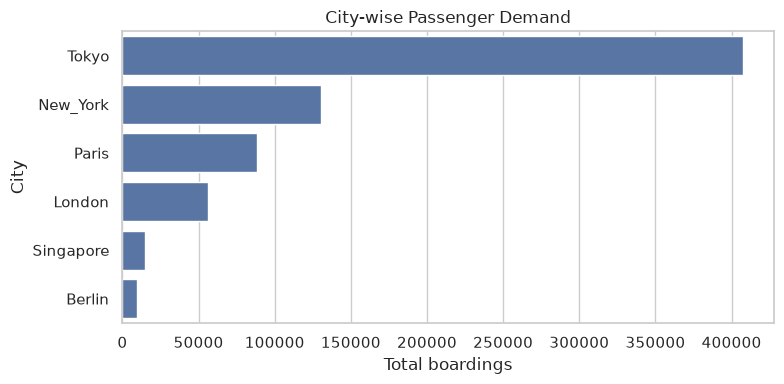

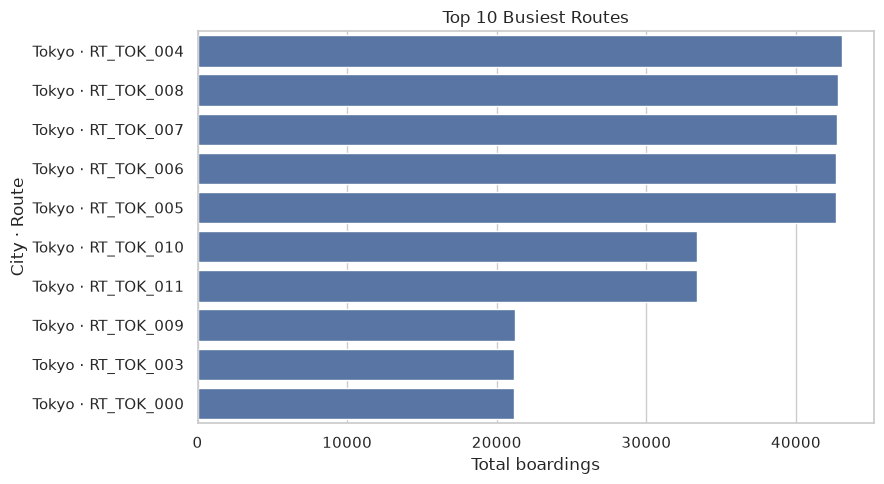

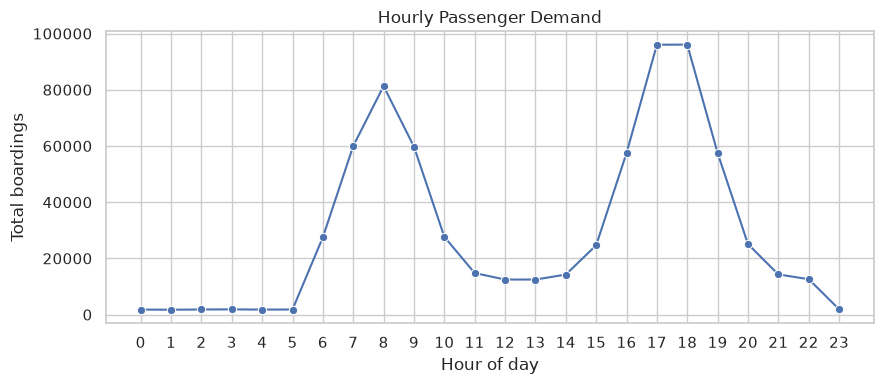

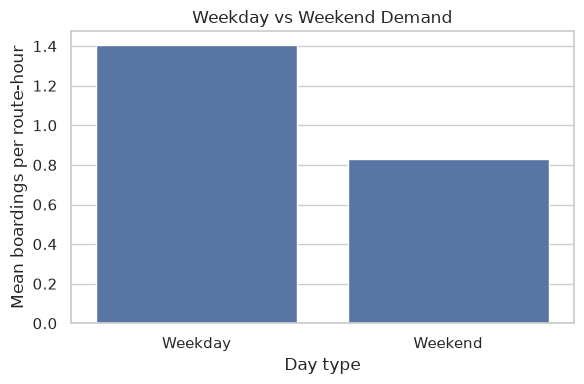

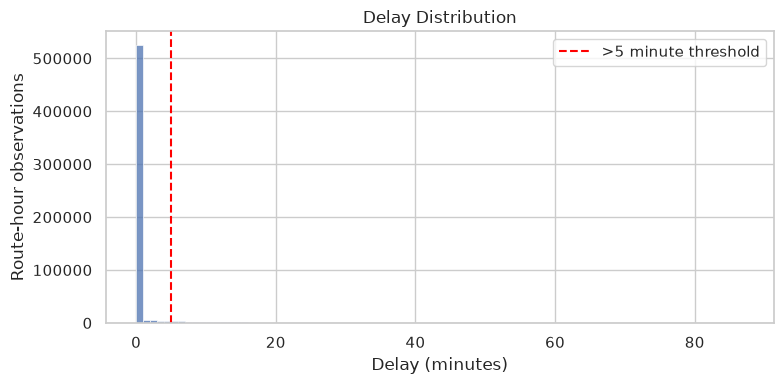

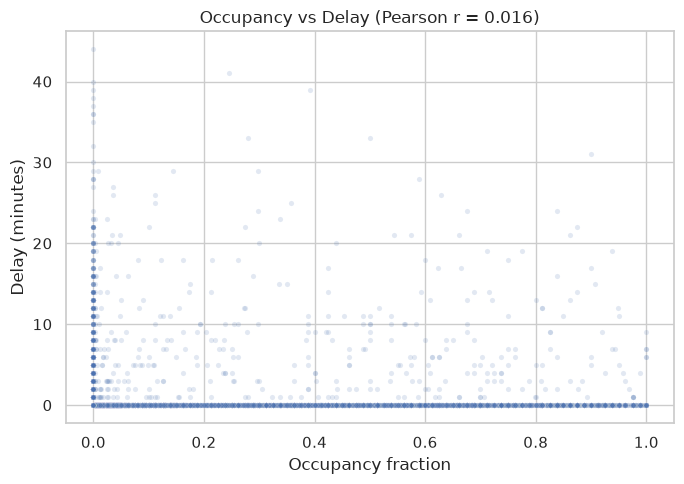

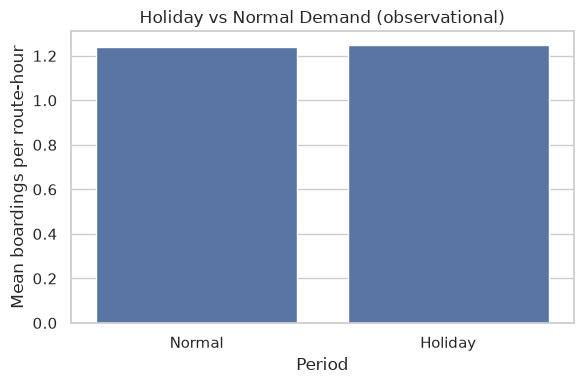

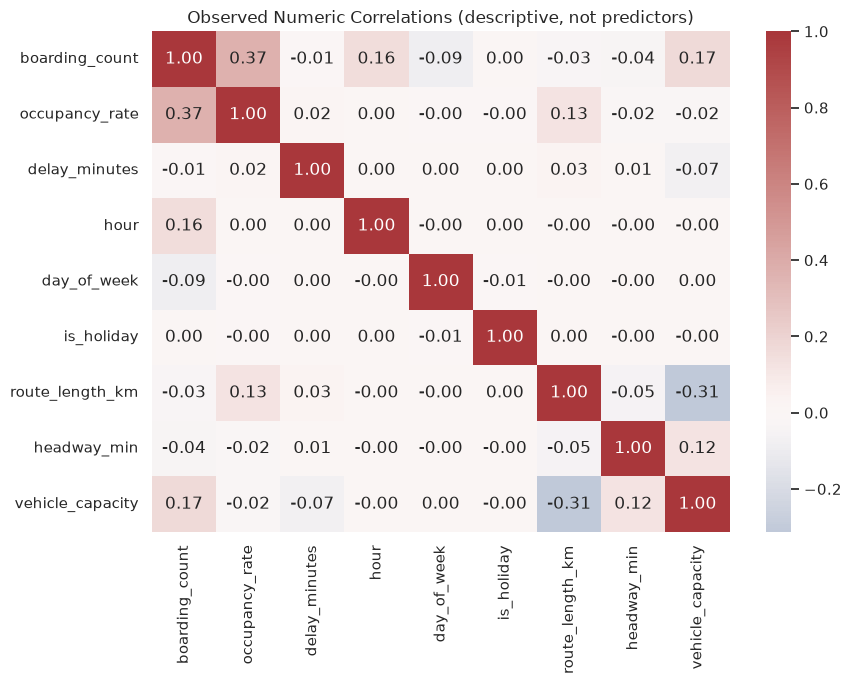

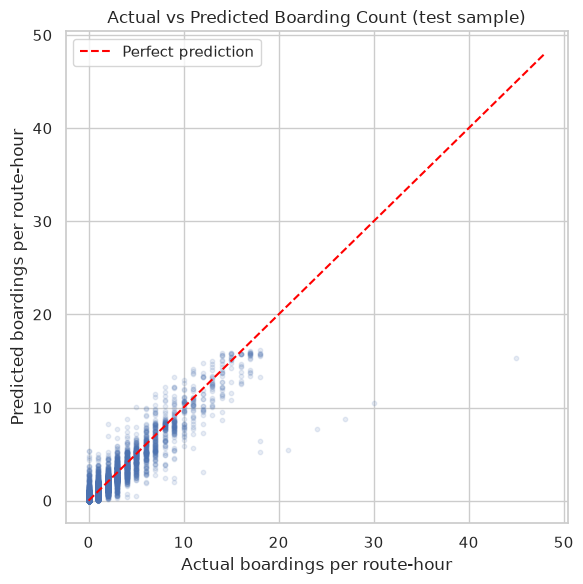

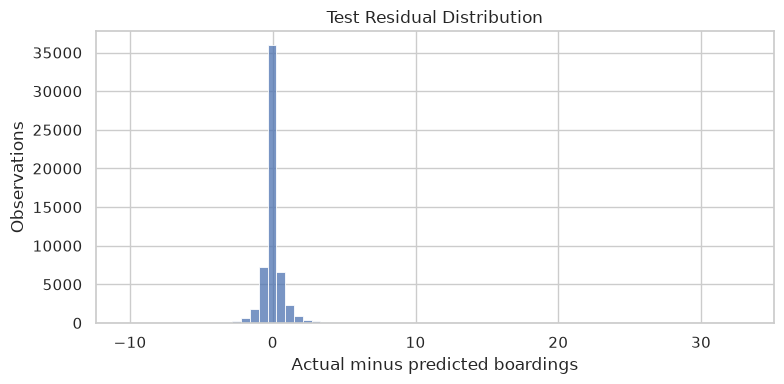

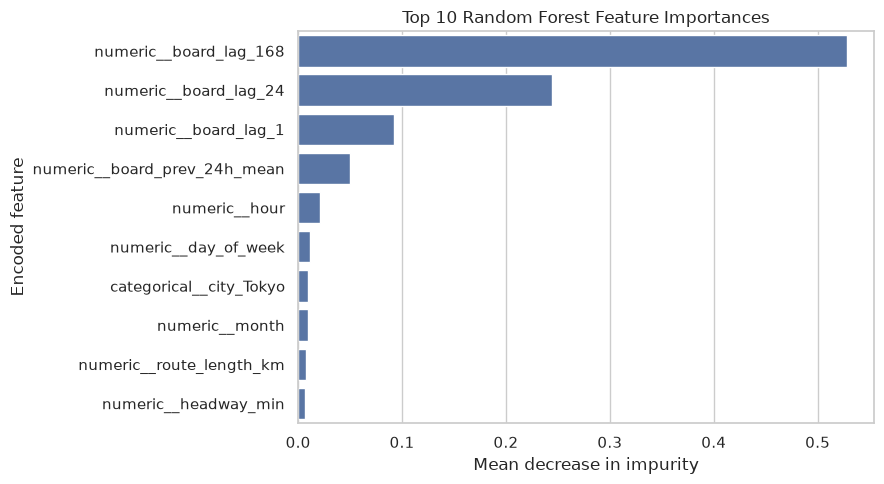

In [13]:
def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURES / name, dpi=150, bbox_inches="tight")
    plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=city_demand["sum"].values, y=city_demand.index, ax=ax)
ax.set(title="City-wise Passenger Demand", xlabel="Total boardings", ylabel="City")
save_figure("city_demand.png")

top_routes = route_demand.head(10)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=top_routes["sum"].values, y=[f"{c} · {r}" for c, r in top_routes.index], ax=ax)
ax.set(title="Top 10 Busiest Routes", xlabel="Total boardings", ylabel="City · Route")
save_figure("top_routes.png")

fig, ax = plt.subplots(figsize=(9, 4))
sns.lineplot(x=hourly_demand.index, y=hourly_demand["sum"], marker="o", ax=ax)
ax.set(title="Hourly Passenger Demand", xlabel="Hour of day", ylabel="Total boardings", xticks=range(24))
save_figure("hourly_demand.png")

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=weekend_comparison.index, y=weekend_comparison["mean"].values, ax=ax)
ax.set(title="Weekday vs Weekend Demand", xlabel="Day type", ylabel="Mean boardings per route-hour")
save_figure("weekend_comparison.png")

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(clean.delay_minutes, bins=range(0, int(clean.delay_minutes.max()) + 2), ax=ax)
ax.axvline(SIGNIFICANT_DELAY_MIN, color="red", linestyle="--", label=">5 minute threshold")
ax.set(title="Delay Distribution", xlabel="Delay (minutes)", ylabel="Route-hour observations")
ax.legend()
save_figure("delay_distribution.png")

sample = clean[["occupancy_rate", "delay_minutes"]].sample(10000, random_state=42)
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=sample, x="occupancy_rate", y="delay_minutes", alpha=0.16, s=14, ax=ax)
ax.set(title=f"Occupancy vs Delay (Pearson r = {occ_delay_pearson:.3f})",
       xlabel="Occupancy fraction", ylabel="Delay (minutes)")
save_figure("occupancy_delay.png")

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=holiday_demand.index, y=holiday_demand["mean"].values, ax=ax)
ax.set(title="Holiday vs Normal Demand (observational)", xlabel="Period", ylabel="Mean boardings per route-hour")
save_figure("holiday_demand.png")

correlation_columns = ["boarding_count", "occupancy_rate", "delay_minutes", "hour", "day_of_week",
                       "is_holiday", "route_length_km", "headway_min", "vehicle_capacity"]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(clean[correlation_columns].corr(), cmap="vlag", center=0, annot=True, fmt=".2f", ax=ax)
ax.set(title="Observed Numeric Correlations (descriptive, not predictors)")
save_figure("correlation_heatmap.png")

plot_idx = np.random.default_rng(42).choice(len(test), size=min(10000, len(test)), replace=False)
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(test.boarding_count.to_numpy()[plot_idx], test_prediction[plot_idx], alpha=0.13, s=10)
axis_max = max(float(test.boarding_count.max()), float(test_prediction.max()))
ax.plot([0, axis_max], [0, axis_max], color="red", linestyle="--", label="Perfect prediction")
ax.set(title="Actual vs Predicted Boarding Count (test sample)", xlabel="Actual boardings per route-hour",
       ylabel="Predicted boardings per route-hour")
ax.legend()
save_figure("actual_vs_predicted.png")

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(test.boarding_count.to_numpy() - test_prediction, bins=70, ax=ax)
ax.set(title="Test Residual Distribution", xlabel="Actual minus predicted boardings", ylabel="Observations")
save_figure("residual_distribution.png")

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=importance.head(10).values, y=importance.head(10).index, ax=ax)
ax.set(title="Top 10 Random Forest Feature Importances", xlabel="Mean decrease in impurity", ylabel="Encoded feature")
save_figure("feature_importances.png")

## 8. Business insights
Findings below are computed from the tables above. These are patterns in synthetic data,
not estimates of real-world demand or proof that holidays or occupancy cause changes.

In [14]:
top_city, low_city = city_demand.index[0], city_demand.index[-1]
top_route_city, top_route_id = route_demand.index[0]
peak_hour = int(hourly_demand["sum"].idxmax())
top_delay_city, top_delay_route = delay_routes.index[0]
holiday_pct = 100 * (holiday_demand.loc["Holiday", "mean"] / holiday_demand.loc["Normal", "mean"] - 1)
findings = [
    f"City concentration: {top_city} recorded {city_demand.iloc[0]['sum']:,.0f} boardings versus "
    f"{low_city}'s {city_demand.iloc[-1]['sum']:,.0f}; allocate analysis capacity by observed route-hour demand.",
    f"Busiest route: {top_route_city} {top_route_id} recorded {route_demand.iloc[0]['sum']:,.0f} boardings; "
    "review its scheduled capacity first.",
    f"Peak hour: {peak_hour:02d}:00 recorded {hourly_demand.loc[peak_hour, 'sum']:,.0f} boardings; "
    "target timetable review around this hour.",
    f"Weekend mean route-hour demand differs by {weekend_pct:+.1f}% from weekdays "
    f"({weekend_comparison.loc['Weekend','mean']:.3f} versus {weekend_comparison.loc['Weekday','mean']:.3f}); "
    "use day-type schedules.",
    f"Repeated delays: {top_delay_city} {top_delay_route} exceeded five minutes in "
    f"{delay_routes.iloc[0]['significant_hours']:,.0f} route-hours; investigate reliability there.",
    f"Holiday mean demand differs by {holiday_pct:+.1f}% from normal periods "
    f"({holiday_demand.loc['Holiday','mean']:.3f} versus {holiday_demand.loc['Normal','mean']:.3f}); "
    "check city, day and hour strata before changing service.",
]
for i, finding in enumerate(findings, 1):
    print(f"{i}. {finding}")
print("Two strongest assessment insights: city concentration and peak hour.")

1. City concentration: Tokyo recorded 407,473 boardings versus Berlin's 9,733; allocate analysis capacity by observed route-hour demand.
2. Busiest route: Tokyo RT_TOK_004 recorded 43,063 boardings; review its scheduled capacity first.
3. Peak hour: 18:00 recorded 96,072 boardings; target timetable review around this hour.
4. Weekend mean route-hour demand differs by -40.8% from weekdays (0.831 versus 1.404); use day-type schedules.
5. Repeated delays: Paris RT_PAR_004 exceeded five minutes in 651 route-hours; investigate reliability there.
6. Holiday mean demand differs by +0.5% from normal periods (1.248 versus 1.241); check city, day and hour strata before changing service.
Two strongest assessment insights: city concentration and peak hour.


## 9. Recommendations
1. **Demand-based bus scheduling:** use the observed peak hour and city/route ranking to
   prioritize a *trial* of extra bus capacity on high-demand bus routes. Any wait-time or
   crowding reduction is hypothetical and requires a real pilot and capacity data.
2. **Delay reduction:** investigate the route with the most >5-minute delayed hours, then
   pilot timetable spacing or traffic-priority measures. The data show delay frequency, not
   the cause or the impact of any intervention.